# Phase 07 — Tiny-Object Definition (Part 1A)

**Phase ID:** `phase_07_tiny_object_definition`
**Part:** 1A — Historical-Definition Audit + CLEAN-v3 **TRAIN-ONLY** Object-Size Taxonomy Design
**Model:** Gemini 3.1 Pro High
**Project Root:** `D:\Softfors\jup` · **Kernel:** `jup-venv`

**Active development manifest:** `phase4_v3` · **Historical manifest:** `phase4_v2`

> **This notebook does NOT freeze a threshold.** All taxonomies below are
> **exploratory candidates**. Any recommendation is
> `RECOMMENDED_FOR_SUPERVISOR_REVIEW` only. Final freeze requires Part 1B authorization.

## 2. Scientific Question

1. What exactly did the historical project mean by **Tiny / Small / Medium / Large**?
2. Can that definition be reconstructed with provenance?
3. What is the correct **unit** of analysis — connected component (object) or case?
4. How should the two radically different acquisition regimes (FULL_FIELD vs ROI) be handled?
5. Which **CLEAN-v3 TRAIN-only** candidate taxonomy is most defensible going forward?

Threshold-design evidence is drawn **only** from KUB TRAIN. VAL is evaluation data and is
**not** used to choose any boundary.

## 3. Governance

| Rule | Value |
|---|---|
| Threshold-design population | `manifests/phase4_v3/train.csv` (KUB TRAIN only) |
| VAL usage | **NOT used for threshold selection** |
| TEST usage | manifest **metadata only** |
| TEST content reads | **0** |
| TEST visualizations | **0** |
| TEST metrics | **0** |
| Threshold frozen | **NO** |
| Training / inference | **NONE** |
| Mask foreground rule | **`mask > 0`** |
| Phase 08 | **NOT started** |

Historical definitions are **not** silently inherited; they are audited and re-applied
explicitly, with the result labelled `HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN`.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
CODE_DIR = PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_07_tiny_object_definition' / 'code'
TABLES = PROJECT_ROOT / 'reports' / 'tables'
AUDITS = PROJECT_ROOT / 'reports' / 'audits'
FIGDIR = PROJECT_ROOT / 'reports' / 'figures' / 'phase07_tiny_object_definition'
sys.path.insert(0, str(CODE_DIR))
import phase07_tiny_definition as p7

print('python :', sys.version.split()[0])
print('pandas :', pd.__version__)
print('module :', p7.__file__)
print()
print('ACTIVE MANIFEST   :', p7.ACTIVE_MANIFEST_VERSION)
print('HISTORICAL MANIFEST:', p7.HISTORICAL_MANIFEST_VERSION)

python : 3.11.9
pandas : 3.0.5
module : D:\Softfors\jup\notebooks\phasewise\phase_07_tiny_object_definition\code\phase07_tiny_definition.py

ACTIVE MANIFEST   : phase4_v3
HISTORICAL MANIFEST: phase4_v2


## 4. Historical-Definition Audit

The historical taxonomy is reconstructed from project sources — **not from memory**.

In [2]:
hist_audit = p7.historical_definition_audit()
print('DEFINITION FOUND:', hist_audit['definition_found'])
print('DISAGREEMENTS   :', len(hist_audit['disagreements']))
print()
display(pd.DataFrame(hist_audit['sources'])[['source_file', 'exists', 'sha256']])
print()
t = p7.HISTORICAL_TAXONOMY
for k in ['taxonomy_version', 'metric', 'metric_definition', 'unit', 'connectivity',
          'coordinate_system', 'acquisition_scope', 'source_split',
          'source_manifest_version', 'source_full_field_component_count',
          'boundary_semantics']:
    print(f'{k:34s}: {t[k]}')
print()
print('THRESHOLDS: Q25=%r  Q50=%r  Q75=%r' % (t['Q25'], t['Q50'], t['Q75']))
for k, v in t['boundaries'].items():
    print(f'  {k:7s}: {v}')

DEFINITION FOUND: True
DISAGREEMENTS   : 0



,source_file,exists,sha256
0,src/analysis/kub_object_size.py,True,4dbf35d074cfe505f43ed3fe6325557b9cb0da900cdb84...
1,src/analysis/kub_characterization.py,True,7726f70dfe2470d23a9e1df7eca5c8fc7a3f884d1a02fb...
2,src/data/transforms.py,True,8a8b636b58843d36810ebf5f3527a8ca1287b93483b962...
3,reports/audits/kub_object_size_thresholds.json,True,20d3ba58fd5d1272aa52c7c6f82a074b1c903d38de8896...
4,reports/audits/kub_object_size_provenance.json,True,024d36495a1062cbc9fd2beb5500a910411997cbe3b473...
5,reports/tables/kub_size_thresholds_v2.csv,True,d93ca6cf9ccc64d2f56580236fec8cb3686bed1f51227d...
6,reports/tables/kub_size_distribution_train_val...,True,c81f4ef935543f3a3dff33eafb0227b47561897db9da6d...
7,reports/tables/kub_size_distribution_by_catego...,True,35939755daa39d846e4e7421766363e57280f68461a8c2...
8,notebooks/05_kub_object_size_taxonomy.ipynb,True,760d62a4d323d2c0f963a8c5c48e3ae3dd7827eff38f96...
9,scripts/legacy/run_phase7_analysis.py,True,b8f88fa993062080dfee04fb51e642b0c80a8d82403383...



taxonomy_version                  : kub_size_v1
metric                            : component_ratio
metric_definition                 : component_pixels / (native_image_height * native_image_width)
unit                              : object (connected foreground component)
connectivity                      : 8
coordinate_system                 : native image pixels, normalized by native image area
acquisition_scope                 : FULL_FIELD only (ROI components were not primary-binned)
source_split                      : TRAIN
source_manifest_version           : phase4_v2
source_full_field_component_count : 1162
boundary_semantics                : lower-inclusive / upper-exclusive cumulative: a value exactly equal to a quartile falls into the LOWER bin

THRESHOLDS: Q25=0.0001499766777599  Q50=0.00033976472454305  Q75=0.0008266496069636999
  TINY   : component_ratio <= Q25
  SMALL  : Q25 < component_ratio <= Q50
  MEDIUM : Q50 < component_ratio <= Q75
  LARGE  : component_ratio > Q7

### 4b. Critical question — which metric was used?

The historical metric is **connected-component area normalized by native image area**
(`component_ratio`), **not** a raw pixel threshold and **not** a 512-canvas threshold.

In [3]:
qa = hist_audit['critical_question_answers']
for k, v in qa.items():
    if k != 'conclusion':
        print(f'{k:26s}: {v}')
print()
print('CONCLUSION:', qa['conclusion'])
print()
print('RESIZE CONVENTION')
for k, v in hist_audit['resize_convention'].items():
    print(f'  {k:28s}: {v}')

A_native_pixels           : PARTIAL — native pixels, but NORMALIZED by native image area
B_512_representation      : NO — the taxonomy used native masks; 512 resize+pad is a separate training-pipeline transform
C_bbox_width              : NO
D_bbox_height             : NO
E_bbox_max_side           : NO
F_bbox_area               : NO (bbox geometry is recorded but not the taxonomy metric)
G_component_area          : YES — connected-component area, normalized as a fraction of native image area (component_ratio)
H_equivalent_diameter     : NO
I_foreground_fraction     : NO (case-level total foreground is separate)

CONCLUSION: The historical metric is G: connected-component area normalized by native image area (component_ratio). The "<32 px" hypothesis is NOT supported by any canonical source.

RESIZE CONVENTION
  taxonomy                    : native resolution, no resize
  training_pipeline           : aspect-ratio-preserving resize + centre pad to 512x512 (scale = min(512/w, 512/h); rw=

## 5. Unit of Analysis: Object vs Case

Historical code assigns size to **individual connected components** (8-connectivity).
ROI components were **not** primary-binned (they carried `ROI_NOT_PRIMARY_BINNED`).
A case-level view existed as derived flags (`contains_*_object`) plus
`dominant_object_stratum` from the largest component.

Both representations are preserved here so downstream object-recall work keeps
object-level labels.

In [4]:
print('Historical object-level convention :', t['unit'])
print('Historical case-level convention   :', t['case_level_convention'])
print('Historical ROI handling            :', t['roi_handling'])
print()
print('CLEAN-v3 decision: BOTH representations are retained.')
print('  - object-level  -> phase07_kub_v3_train_object_geometry.csv')
print('  - case-level    -> phase07_kub_v3_train_case_size_summary.csv')

Historical object-level convention : object (connected foreground component)
Historical case-level convention   : per-case flags contains_{tiny,small,medium,large}_object plus dominant_object_stratum from the largest component
Historical ROI handling            : ROI_NOT_PRIMARY_BINNED

CLEAN-v3 decision: BOTH representations are retained.
  - object-level  -> phase07_kub_v3_train_object_geometry.csv
  - case-level    -> phase07_kub_v3_train_case_size_summary.csv


## 6. CLEAN-v3 TRAIN Population

In [5]:
train = p7.load_manifest('train')
test = p7.load_manifest('test')          # metadata only, never decoded
ktr = p7.kub_only(train)
ktest = p7.kub_only(test)
print('KUB TRAIN cases   :', len(ktr), '(expected', p7.EXPECTED_KUB_TRAIN, ')')
print('KUB TRAIN patients:', ktr['patient_id'].nunique())
print('KUB TEST (metadata only):', len(ktest))
assert len(ktr) == p7.EXPECTED_KUB_TRAIN, 'CHECK_REQUIRED: TRAIN count mismatch'
print()
print('HARD GATE PASS: KUB TRAIN == 1978')

KUB TRAIN cases   :

 1978 (expected 1978 )
KUB TRAIN patients: 318
KUB TEST (metadata only): 558

HARD GATE PASS: KUB TRAIN == 1978


## 7. The Acquisition-Regime Issue

Phase 06 established that the KUB corpus mixes two strongly different regimes.
Native-pixel thresholds are therefore **not** transferable between them.

### 7b. Conceptual strategies

| Option | Description | Advantages | Limitations | Historical compatibility | Downstream compatibility |
|---|---|---|---|---|---|
| **A** | Taxonomy only for FULL_FIELD objects | Matches historical scope exactly; native geometry meaningful | ROI objects left unbinned | **Exact** (this is what history did) | High — historical object recall was FULL_FIELD-only |
| **B** | One normalized metric usable across both regimes | Covers all objects; scale-invariant | ROI denominator is the crop, so the ratio reflects magnification | None (new metric) | Good — still object-level |
| **C** | Separate acquisition-specific taxonomies | Each regime gets a tailored rule | Two rules to maintain; no shared meaning | Partial | Moderate — complicates comparison |

**No option is selected here.** The candidates below operationalise A (C1/C3) and B (C2).

## 8. Geometry Coordinate Systems

Objects are measured in three coordinate systems:

1. **native** — pixels in the original image
2. **normalized** — divided by native image dimensions (scale-invariant)
3. **512 model canvas** — the documented historical preprocessing
   (`scale = min(512/w, 512/h)`, aspect-preserving resize + centre pad)

In [6]:
print('Documented preprocessing (src/data/transforms.py):')
print('  scale = min(size/width, size/height)')
print('  rw, rh = round(width*scale), round(height*scale)')
print('  bilinear image resize, NEAREST mask resize, centre pad to 512x512')
print()
print('This is ASPECT-RATIO-PRESERVING resize + pad — NOT a non-isotropic stretch.')
print('The 512 projection is therefore a pure isotropic scaling of native geometry.')
print()
print('Mask binarization in that pipeline is already `> 0`, matching Phase-06 semantics.')

Documented preprocessing (src/data/transforms.py):
  scale = min(size/width, size/height)
  rw, rh = round(width*scale), round(height*scale)
  bilinear image resize, NEAREST mask resize, centre pad to 512x512

This is ASPECT-RATIO-PRESERVING resize + pad — NOT a non-isotropic stretch.
The 512 projection is therefore a pure isotropic scaling of native geometry.

Mask binarization in that pipeline is already `> 0`, matching Phase-06 semantics.


## 9. TRAIN Object Table

One row per connected foreground component (8-connectivity), TRAIN only.
This computation opens 1,978 TRAIN masks and may take a few minutes.

In [7]:
obj_df, case_df = p7.build_train_tables(ktr)
obj_df = p7.apply_historical_taxonomy(obj_df)
p7.write_table(obj_df, 'phase07_kub_v3_train_object_geometry.csv', TABLES)
print('objects:', len(obj_df))
print('columns:', list(obj_df.columns))
display(obj_df.head(5))

objects: 2375
columns: ['sample_id', 'patient_id', 'category', 'acquisition_type', 'component_index', 'component_pixels', 'component_ratio', 'component_fraction', 'bbox_x', 'bbox_y', 'bbox_width', 'bbox_height', 'bbox_max_side', 'bbox_area', 'bbox_area_fraction', 'equivalent_diameter', 'normalized_equivalent_diameter', 'normalized_bbox_width', 'normalized_bbox_height', 'normalized_bbox_max_side', 'bbox_width_512', 'bbox_height_512', 'bbox_max_side_512', 'bbox_area_512', 'equivalent_diameter_512', 'model_canvas_scale', 'historical_stratum', 'historical_reference_stratum', 'historical_label']


,sample_id,patient_id,category,acquisition_type,component_index,component_pixels,component_ratio,component_fraction,bbox_x,bbox_y,...,normalized_bbox_max_side,bbox_width_512,bbox_height_512,bbox_max_side_512,bbox_area_512,equivalent_diameter_512,model_canvas_scale,historical_stratum,historical_reference_stratum,historical_label
0,ecb2b0b5e962b0642665cd8b2da8f23b,patient-00003,Bladder_Stone,FULL_FIELD,1,4763,0.000505,0.000505,1561,2144,...,0.029948,12.333333,15.333333,15.333333,189.111111,12.979086,0.166667,MEDIUM,MEDIUM,HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN
1,84d7aa903794899c130127bb8b835ba0,patient-00004,Bladder_Stone,FULL_FIELD,1,4148,0.000440,0.000440,1279,2591,...,0.024414,12.500000,12.333333,12.500000,154.166667,12.112204,0.166667,MEDIUM,MEDIUM,HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN
2,63c84da18b33b023ab32c7374f27f74d,patient-00005,Bladder_Stone,FULL_FIELD,1,616,0.000065,0.000065,1455,2415,...,0.010742,5.000000,5.500000,5.500000,27.500000,4.667606,0.166667,TINY,TINY,HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN
3,c1a6cb8932380bdcae3dbe81e095ef81,patient-00006,Bladder_Stone,FULL_FIELD,1,4827,0.000511,0.000511,2217,952,...,0.034831,17.833333,12.166667,17.833333,216.972222,13.065994,0.166667,MEDIUM,MEDIUM,HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN
4,c1a6cb8932380bdcae3dbe81e095ef81,patient-00006,Bladder_Stone,FULL_FIELD,2,1366,0.000145,0.000145,2217,1020,...,0.018229,5.833333,9.333333,9.333333,54.444444,6.950710,0.166667,TINY,TINY,HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN


## 10. TRAIN Case Table

In [8]:
p7.write_table(case_df, 'phase07_kub_v3_train_case_size_summary.csv', TABLES)
print('cases:', len(case_df))
display(case_df.head(5))
print()
print('multi-component cases:', int((case_df['component_count'] >= 2).sum()),
      '(expected', p7.EXPECTED_MULTI_COMPONENT_TRAIN, ')')

cases: 1978


,sample_id,patient_id,category,acquisition_type,native_width,native_height,component_count,total_foreground_pixels,foreground_fraction,largest_component_pixels,largest_component_fraction,largest_component_bbox_width,largest_component_bbox_height,largest_component_bbox_max_side,largest_component_bbox_area_fraction,largest_component_equivalent_diameter,largest_component_ratio
0,ecb2b0b5e962b0642665cd8b2da8f23b,patient-00003,Bladder_Stone,FULL_FIELD,3072,3072,1,4763,0.000505,4763,0.000505,74,92,92,0.000721,77.874514,0.000505
1,84d7aa903794899c130127bb8b835ba0,patient-00004,Bladder_Stone,FULL_FIELD,3072,3072,1,4148,0.000440,4148,0.000440,75,74,75,0.000588,72.673225,0.000440
2,63c84da18b33b023ab32c7374f27f74d,patient-00005,Bladder_Stone,FULL_FIELD,3072,3072,1,616,0.000065,616,0.000065,30,33,33,0.000105,28.005634,0.000065
3,c1a6cb8932380bdcae3dbe81e095ef81,patient-00006,Bladder_Stone,FULL_FIELD,3072,3072,5,15716,0.001665,4859,0.000515,58,118,118,0.000725,78.655394,0.000515
4,8acc4520aa544aaf550a08e16c3b37f2,patient-00008,Bladder_Stone,FULL_FIELD,3072,3072,1,478,0.000051,478,0.000051,24,26,26,0.000066,24.669992,0.000051



multi-component cases: 210 (expected 212 )


## 11. TRAIN Size Distributions (stratified)

Quantiles are reported **stratified by acquisition regime**, and by anatomical
category within FULL_FIELD. Acquisition regimes are never pooled without showing
the stratification.

In [9]:
metrics = ['component_ratio', 'component_pixels', 'equivalent_diameter',
           'normalized_equivalent_diameter', 'bbox_max_side', 'bbox_area_fraction',
           'equivalent_diameter_512']
q_df = p7.stratified_quantiles(obj_df, metrics)
p7.write_table(q_df, 'phase07_kub_v3_train_size_quantiles.csv', TABLES)
display(q_df[q_df['metric'] == 'component_ratio'])
print()
display(q_df[q_df['metric'] == 'equivalent_diameter'])

,metric,group,n,P01,P05,P10,P25,P50,P75,P90,P95,P99,min,max
0,component_ratio,ALL_TRAIN,2375,0.000056,0.000090,0.000128,0.000350,0.141243,0.303702,0.401101,0.448177,0.540936,0.000027,0.658871
1,component_ratio,FULL_FIELD,1161,0.000050,0.000069,0.000090,0.000150,0.000340,0.000828,0.002514,0.004030,0.009637,0.000027,0.017036
2,component_ratio,ROI,1214,0.117016,0.159615,0.185146,0.233017,0.300635,0.377419,0.447488,0.490438,0.553979,0.000218,0.658871
3,component_ratio,FULL_FIELD | Bladder_Stone,343,0.000045,0.000056,0.000065,0.000086,0.000122,0.000188,0.000357,0.000589,0.001522,0.000027,0.002736
4,component_ratio,FULL_FIELD | Kidney_Stone,709,0.000069,0.000124,0.000178,0.000281,0.000572,0.001542,0.003431,0.005729,0.011350,0.000031,0.017036
5,component_ratio,FULL_FIELD | Ureteric_Stone,109,0.000041,0.000069,0.000105,0.000175,0.000357,0.000523,0.000746,0.000964,0.001419,0.000032,0.001484


,metric,group,n,P01,P05,P10,P25,P50,P75,P90,P95,P99,min,max
12,equivalent_diameter,ALL_TRAIN,2375,22.375474,26.050656,29.725885,38.039935,54.572038,85.347542,147.333564,184.763733,329.478092,1.595769,408.892289
13,equivalent_diameter,FULL_FIELD,1161,22.482689,26.050656,29.640096,38.065031,55.554772,85.994042,147.959727,185.696383,328.468327,18.159544,406.858542
14,equivalent_diameter,ROI,1214,22.338887,26.098243,29.924393,38.019010,54.314781,85.024320,146.458441,182.048972,327.511695,1.595769,408.892289
15,equivalent_diameter,FULL_FIELD | Bladder_Stone,343,21.719880,23.915245,25.412339,29.152826,34.503318,41.826024,56.854295,74.852396,121.713509,18.159544,152.025801
16,equivalent_diameter,FULL_FIELD | Kidney_Stone,709,25.906397,35.070606,39.807961,50.550883,71.640970,119.953658,176.524091,224.954037,335.881909,19.314740,406.858542
17,equivalent_diameter,FULL_FIELD | Ureteric_Stone,109,22.101171,28.393911,33.829487,42.699872,56.407673,66.746275,80.092668,90.202216,109.465535,19.544100,111.988435


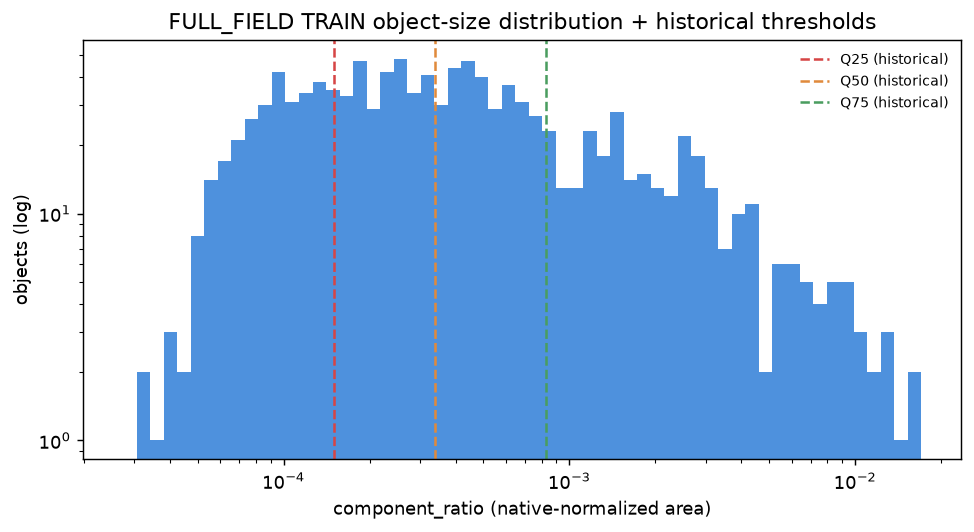

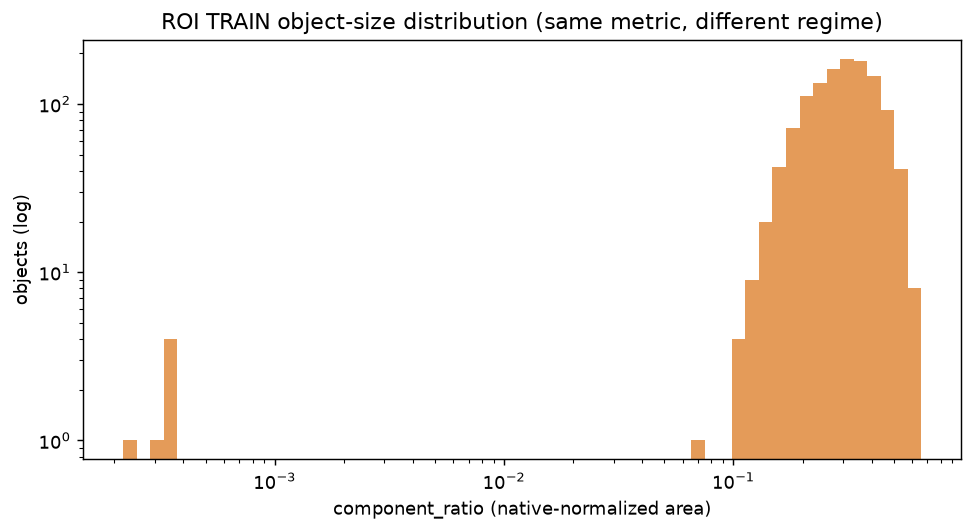

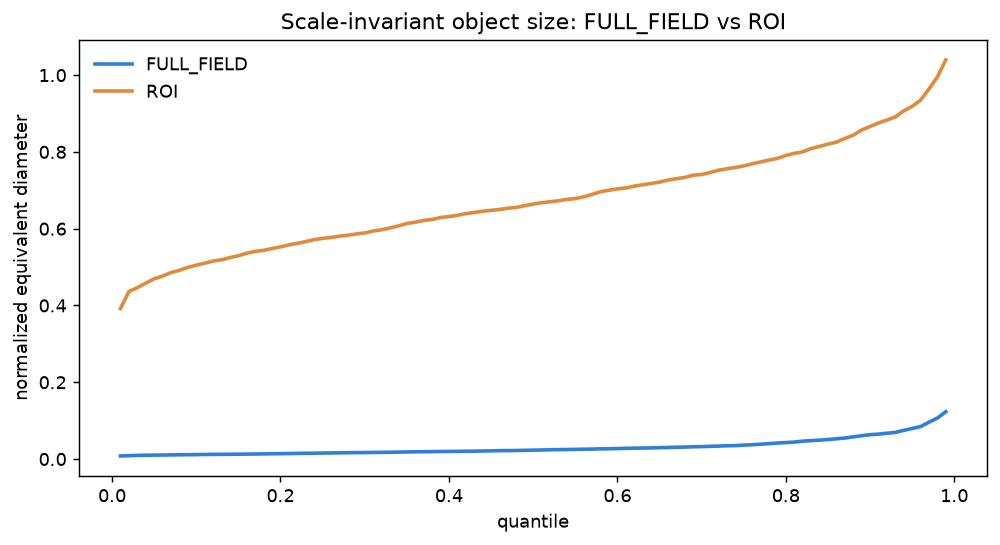

In [10]:
for fname, cap in [
    ('phase07_ff_object_size_distribution.png', 'Figure 1 — FULL_FIELD object-size distribution + historical thresholds'),
    ('phase07_roi_object_size_distribution.png', 'Figure 2 — ROI object-size distribution'),
    ('phase07_normalized_size_comparison.png', 'Figure 3 — Scale-invariant size: FULL_FIELD vs ROI'),
]:
    display(IPImage(filename=str(FIGDIR / fname)))

## 12. Historical Definition Applied to CLEAN-v3 TRAIN

Result label: `HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN`.

In [11]:
ff = obj_df[obj_df['acquisition_type'] == 'FULL_FIELD']
counts = ff['historical_stratum'].value_counts().reindex(list(p7.STRATA), fill_value=0)
n = int(counts.sum())
hist_summary = pd.DataFrame({
    'stratum': list(p7.STRATA),
    'objects': [int(counts[s]) for s in p7.STRATA],
    'prevalence_pct': [100.0 * counts[s] / n for s in p7.STRATA],
})
display(hist_summary)
print('FULL_FIELD objects:', n)
print('label: HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN')
print()
print('By category (FULL_FIELD):')
display(pd.crosstab(ff['category'], ff['historical_stratum'])[list(p7.STRATA)])
print()
print('NOTE: no VAL prevalence is computed here (VAL is evaluation data only).')

,stratum,objects,prevalence_pct
0,TINY,291,25.064599
1,SMALL,289,24.892334
2,MEDIUM,290,24.978467
3,LARGE,291,25.064599


FULL_FIELD objects: 1161
label: HISTORICAL_DEFINITION_APPLIED_TO_CLEAN_v3_TRAIN

By category (FULL_FIELD):


historical_stratum,TINY,SMALL,MEDIUM,LARGE
category,,,,
Bladder_Stone,221,84,31,7
Kidney_Stone,48,173,212,276
Ureteric_Stone,22,32,47,8



NOTE: no VAL prevalence is computed here (VAL is evaluation data only).


## 13. Candidate Taxonomy Designs

All candidates are **exploratory**. All cut points are derived from
**TRAIN FULL_FIELD objects only**, matching the historical source population.
**No VAL data is used.**

In [12]:
candidates = p7.build_candidates(obj_df)
cand_sum = p7.candidate_summary(obj_df, candidates)
for c in candidates:
    print('=' * 68)
    print(c['candidate_id'], '—', c['name'])
    print('  metric       :', c['metric'])
    print('  definition   :', c['metric_definition'])
    print('  unit         :', c['unit'])
    print('  coords       :', c['coordinate_system'])
    print('  acquisition  :', c['acquisition_applicability'])
    print('  cuts         :', [f'{v:.6g}' for v in c['cut_values']])
    for k, v in c['boundaries'].items():
        print(f'    {k:7s}: {v}')
    print('  advantages   :', c['advantages'][0])
    print('  limitations  :', c['limitations'][0])
    print('  historical   :', c['historical_compatibility'])

C1_HISTORICAL_kub_size_v1 — Historical kub_size_v1 (faithful)
  metric       : component_ratio
  definition   : component_pixels / (native_image_height * native_image_width)
  unit         : object (connected component, 8-connectivity)
  coords       : native pixels, normalized by native image area
  acquisition  : FULL_FIELD only (ROI -> ROI_NOT_PRIMARY_BINNED)
  cuts         : ['0.000149977', '0.000339765', '0.00082665']
    TINY   : x <= 0.0001499766777599
    SMALL  : 0.0001499766777599 < x <= 0.00033976472454305
    MEDIUM : 0.00033976472454305 < x <= 0.0008266496069636999
    LARGE  : x > 0.0008266496069636999
  advantages   : Exact continuity with Phases 06-14 historical evidence
  limitations  : Derived on phase4_v2 FULL_FIELD TRAIN (contaminated-era) components
  historical   : EXACT (same metric, unit, connectivity, boundaries)
C2_NORMALIZED_EQ_DIAMETER — Scale-invariant normalized equivalent diameter
  metric       : normalized_equivalent_diameter
  definition   : equivalent

In [13]:
display(cand_sum[cand_sum['scope'] == 'FULL_FIELD'].pivot_table(
    index='candidate_id', columns='stratum', values='objects', aggfunc='sum'))

stratum,LARGE,MEDIUM,SMALL,TINY
candidate_id,,,,
C1_HISTORICAL_kub_size_v1,291,290,289,291
C2_NORMALIZED_EQ_DIAMETER,290,290,290,291
C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX,290,290,290,291


### 13b. Cross-regime behaviour (critical caveat)

All candidates are calibrated on **FULL_FIELD** objects. Applying them to ROI crops is a
separate question, because an ROI crop *magnifies* its object: the object's share of the
**crop** is not comparable to an object's share of a **whole radiograph**.

In [14]:
piv = cand_sum.pivot_table(index=['candidate_id', 'scope'], columns='stratum',
                          values='objects', aggfunc='sum')
display(piv)
print()
roi_share = {}
for c in candidates:
    sub = cand_sum[(cand_sum['candidate_id'] == c['candidate_id']) &
                   (cand_sum['scope'] == 'ROI')]
    if sub.empty:
        continue
    tot = float(sub['objects'].sum())
    if tot == 0:
        roi_share[c['candidate_id']] = 'no applicable ROI objects (FULL_FIELD-only rule)'
        continue
    roi_share[c['candidate_id']] = {
        s: round(100.0 * float(sub[sub['stratum'] == s]['objects'].iloc[0]) / tot, 2)
        for s in p7.STRATA}
print('ROI objects classified as LARGE when a FULL_FIELD-calibrated rule is applied:')
for k, v in roi_share.items():
    if isinstance(v, dict):
        print(f'  {k:38s} LARGE={v["LARGE"]:6.2f}%  TINY={v["TINY"]:6.2f}%')
    else:
        print(f'  {k:38s} {v}')
print()
print('INTERPRETATION: because ROI crops magnify their object, a FULL_FIELD-calibrated')
print('normalized rule pushes most ROI objects into LARGE. This means C2 is NOT')
print('automatically well-calibrated across regimes merely because its metric is')
print('scale-invariant; a cross-regime rule would need its own ROI-specific calibration')
print('(Option C) or the taxonomy should stay FULL_FIELD-scoped (Option A).')
print()
print('This strengthens Options A/C and weakens the naive reading of Option B.')

stratum                                        LARGE  MEDIUM  SMALL  TINY
candidate_id                       scope                                 
C1_HISTORICAL_kub_size_v1          ALL_TRAIN     291     290    289   291
                                   FULL_FIELD    291     290    289   291
                                   ROI             0       0      0     0
C2_NORMALIZED_EQ_DIAMETER          ALL_TRAIN    1498     292    294   291
                                   FULL_FIELD    290     290    290   291
                                   ROI          1208       2      4     0
C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX ALL_TRAIN     290     290    290   291
                                   FULL_FIELD    290     290    290   291
                                   ROI             0       0      0     0


ROI objects classified as LARGE when a FULL_FIELD-calibrated rule is applied:
  C1_HISTORICAL_kub_size_v1              no applicable ROI objects (FULL_FIELD-only rule)
  C2_NORMALIZED_EQ_DIAMETER              LARGE= 99.51%  TINY=  0.00%
  C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX     no applicable ROI objects (FULL_FIELD-only rule)

INTERPRETATION: because ROI crops magnify their object, a FULL_FIELD-calibrated
normalized rule pushes most ROI objects into LARGE. This means C2 is NOT
automatically well-calibrated across regimes merely because its metric is
scale-invariant; a cross-regime rule would need its own ROI-specific calibration
(Option C) or the taxonomy should stay FULL_FIELD-scoped (Option A).

This strengthens Options A/C and weakens the naive reading of Option B.


## 14. Boundary Sensitivity (TRAIN only)

For each cut, counts immediately either side show whether the boundary sits in a
dense pile-up where small measurement variation would flip many labels.

In [15]:
sens_df = p7.boundary_sensitivity(obj_df, candidates)
p7.write_table(sens_df, 'phase07_candidate_boundary_sensitivity.csv', TABLES)
cols = ['candidate_id', 'metric', 'boundary', 'cut_value', 'delta_kind',
        'within_minus_1', 'within_plus_1', 'within_minus_2', 'within_plus_2',
        'pileup_frac_1', 'pileup_frac_2']
display(sens_df[cols])

,candidate_id,metric,boundary,cut_value,delta_kind,within_minus_1,within_plus_1,within_minus_2,within_plus_2,pileup_frac_1,pileup_frac_2
0,C1_HISTORICAL_kub_size_v1,component_ratio,TINY_SMALL,0.000150,relative_fraction_of_cut,17,16,38,29,0.028424,0.057709
1,C1_HISTORICAL_kub_size_v1,component_ratio,SMALL_MEDIUM,0.000340,relative_fraction_of_cut,14,14,33,26,0.024117,0.050818
2,C1_HISTORICAL_kub_size_v1,component_ratio,MEDIUM_LARGE,0.000827,relative_fraction_of_cut,11,13,27,18,0.020672,0.038760
3,C2_NORMALIZED_EQ_DIAMETER,normalized_equivalent_diameter,TINY_SMALL,0.015541,relative_fraction_of_cut,32,29,56,62,0.025684,0.049684
4,C2_NORMALIZED_EQ_DIAMETER,normalized_equivalent_diameter,SMALL_MEDIUM,0.023070,relative_fraction_of_cut,38,27,77,63,0.027368,0.058947
5,C2_NORMALIZED_EQ_DIAMETER,normalized_equivalent_diameter,MEDIUM_LARGE,0.036301,relative_fraction_of_cut,23,20,54,32,0.018105,0.036211
6,C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX,equivalent_diameter,TINY_SMALL,38.065031,pixels,27,26,44,43,0.045650,0.074935
7,C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX,equivalent_diameter,SMALL_MEDIUM,55.554772,pixels,4,17,15,35,0.018088,0.043066
8,C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX,equivalent_diameter,MEDIUM_LARGE,85.994042,pixels,3,5,10,6,0.006891,0.013781


## 15. Multi-Component Implications

Multi-component masks are **not** collapsed. Each component receives its own size
class; case-level views are derived separately.

**Connectivity matters.** The historical taxonomy used **8-connectivity**
(`np.ones((3,3))`). Phase 06 used `scipy.ndimage.label`'s default, which is
**4-connectivity**. Diagonally touching regions merge under 8-connectivity, so the
multi-component case count differs slightly between the two conventions.

In [16]:
multi = case_df[case_df['component_count'] >= 2]
print('multi-component TRAIN cases (8-connectivity, historical convention):', len(multi))
print('Phase-06 reference count (4-connectivity, scipy default)           :',
      p7.EXPECTED_MULTI_COMPONENT_TRAIN)
print()
print('Both are correct for their own convention: 4-connectivity splits diagonally')
print('touching regions into separate components; 8-connectivity merges them.')
print('Phase 07 adopts 8-connectivity to match the historical taxonomy exactly.')
print()
print('max components in a case   :', int(case_df['component_count'].max()))
print('Objects contributed by multi-component cases:',
      int(obj_df[obj_df['sample_id'].isin(multi['sample_id'])].shape[0]))
print()
print('Case-level rules that COULD be defined (none chosen here):')
for rule in ['largest-component class', 'smallest-component class',
             'any-tiny component', 'dominant (largest) component']:
    print('  -', rule)
print()
print('For downstream object recall, object-level labels remain authoritative.')

multi-component TRAIN cases (8-connectivity, historical convention): 210
Phase-06 reference count (4-connectivity, scipy default)           : 212

Both are correct for their own convention: 4-connectivity splits diagonally
touching regions into separate components; 8-connectivity merges them.
Phase 07 adopts 8-connectivity to match the historical taxonomy exactly.

max components in a case   : 11
Objects contributed by multi-component cases: 607

Case-level rules that COULD be defined (none chosen here):
  - largest-component class
  - smallest-component class
  - any-tiny component
  - dominant (largest) component

For downstream object recall, object-level labels remain authoritative.


## 16. Deterministic TRAIN Gallery

Deterministic, prediction-independent selection across acquisition regimes,
anatomical categories and size regions, including objects near candidate
boundaries. **All candidate labels shown are NOT FROZEN.**

In [17]:
sel = p7.deterministic_gallery_selection(obj_df, case_df, n_total=16)
def _lab(row):
    parts = []
    for c in candidates:
        v = row[c['metric']]; cuts = c['cut_values']
        lab = ('TINY' if v <= cuts[0] else 'SMALL' if v <= cuts[1]
               else 'MEDIUM' if v <= cuts[2] else 'LARGE')
        parts.append(f"{c['candidate_id'].split('_')[0]}={lab}")
    return 'NOT FROZEN | ' + ' '.join(parts)
sel['candidate_labels'] = sel.apply(_lab, axis=1)
p7.write_table(sel, 'phase07_train_gallery_selection.csv', TABLES)
SELECTION_SHA = p7.sha256_of_strings(
    (sel['sample_id'] + '#' + sel['component_index'].astype(str)).tolist())
display(sel[['selection_rank', 'sample_id', 'category', 'acquisition_type',
             'component_index', 'component_pixels', 'component_ratio',
             'equivalent_diameter', 'candidate_labels']])
print('gallery cases:', len(sel))
print('selection SHA:', SELECTION_SHA)

,selection_rank,sample_id,category,acquisition_type,component_index,component_pixels,component_ratio,equivalent_diameter,candidate_labels
0,1,00493050556465a8114f4141b84a8534,Bladder_Stone,ROI,1,1334,0.250375,41.212881,NOT FROZEN | C1=LARGE C2=LARGE C3=SMALL
1,2,24d5d3e9664ff970a84ccc08ad4b9f04,Kidney_Stone,FULL_FIELD,1,5494,0.000828,83.637181,NOT FROZEN | C1=LARGE C2=MEDIUM C3=MEDIUM
2,3,35424154e729011089947c51f6a5dde3,Bladder_Stone,ROI,1,869,0.238736,33.263271,NOT FROZEN | C1=LARGE C2=LARGE C3=TINY
3,4,4e125dd29feff9a5a66bf27f77993455,Kidney_Stone,FULL_FIELD,1,5459,0.000823,83.370346,NOT FROZEN | C1=MEDIUM C2=MEDIUM C3=MEDIUM
4,5,66404127f46c6713f1fd3b6e5f3cffc0,Kidney_Stone,FULL_FIELD,1,9000,0.001356,107.047447,NOT FROZEN | C1=LARGE C2=LARGE C3=LARGE
5,6,776e8a18d67468bff36086ca4f3c9d85,Ureteric_Stone,ROI,1,1686,0.304113,46.332298,NOT FROZEN | C1=LARGE C2=LARGE C3=SMALL
6,7,78880b4420a45b93f20800102a825846,Bladder_Stone,ROI,1,4887,0.392121,78.881694,NOT FROZEN | C1=LARGE C2=LARGE C3=MEDIUM
7,8,7dfe8277da9bd1f81fafa69adb3babba,Bladder_Stone,FULL_FIELD,1,488,0.000074,24.926711,NOT FROZEN | C1=TINY C2=TINY C3=TINY
8,9,7f8ff6a340fd02dcad6a058a2a36c501,Ureteric_Stone,FULL_FIELD,1,1417,0.000214,42.475645,NOT FROZEN | C1=SMALL C2=SMALL C3=SMALL
9,10,80dd4c89c35f880d58d2777dd8535bd4,Ureteric_Stone,FULL_FIELD,1,1313,0.000151,40.887205,NOT FROZEN | C1=SMALL C2=SMALL C3=SMALL


gallery cases: 16
selection SHA: 150a8f24c8e30ca92babeb94477bf07dfb6264cfceeed24ae53465d4e55bfe06


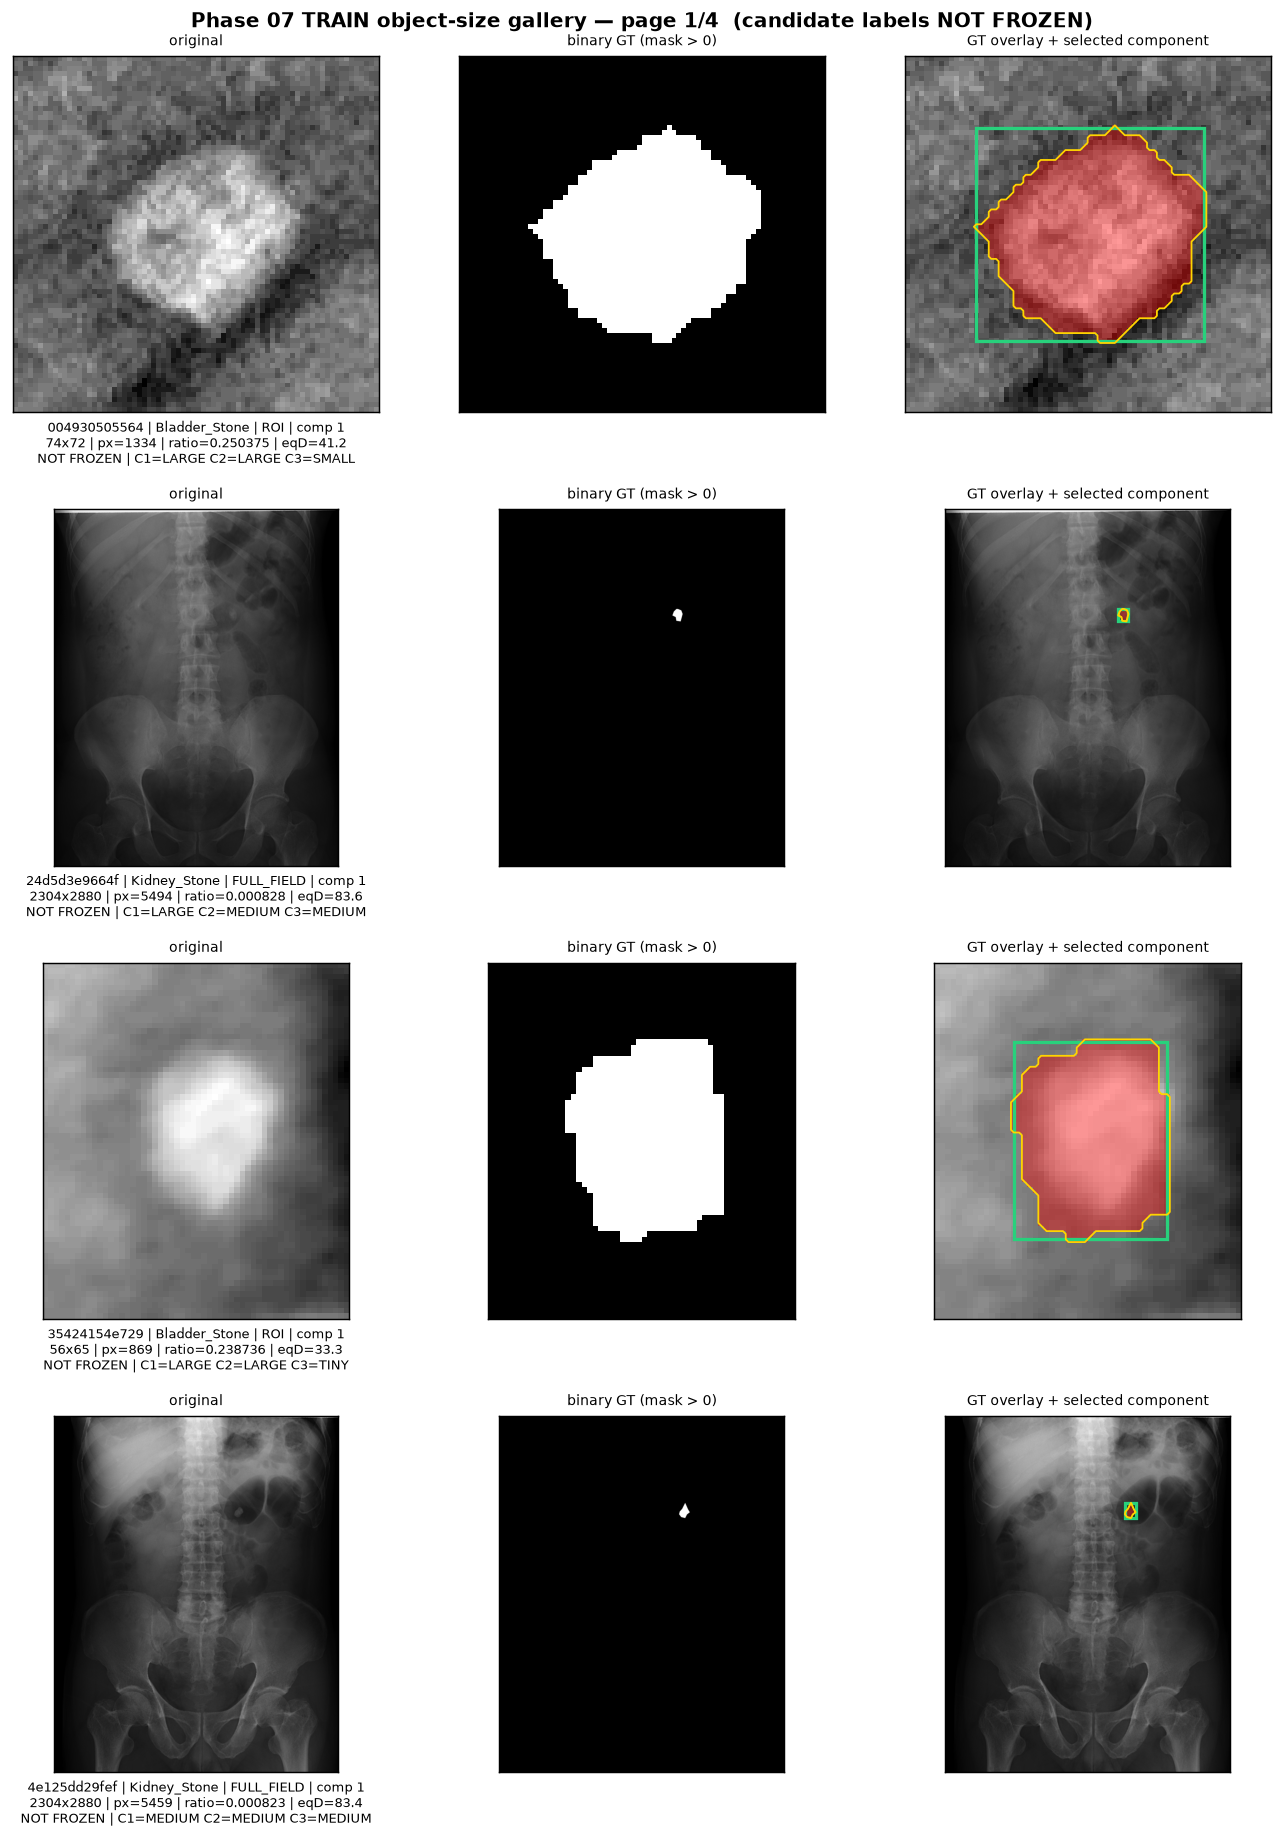

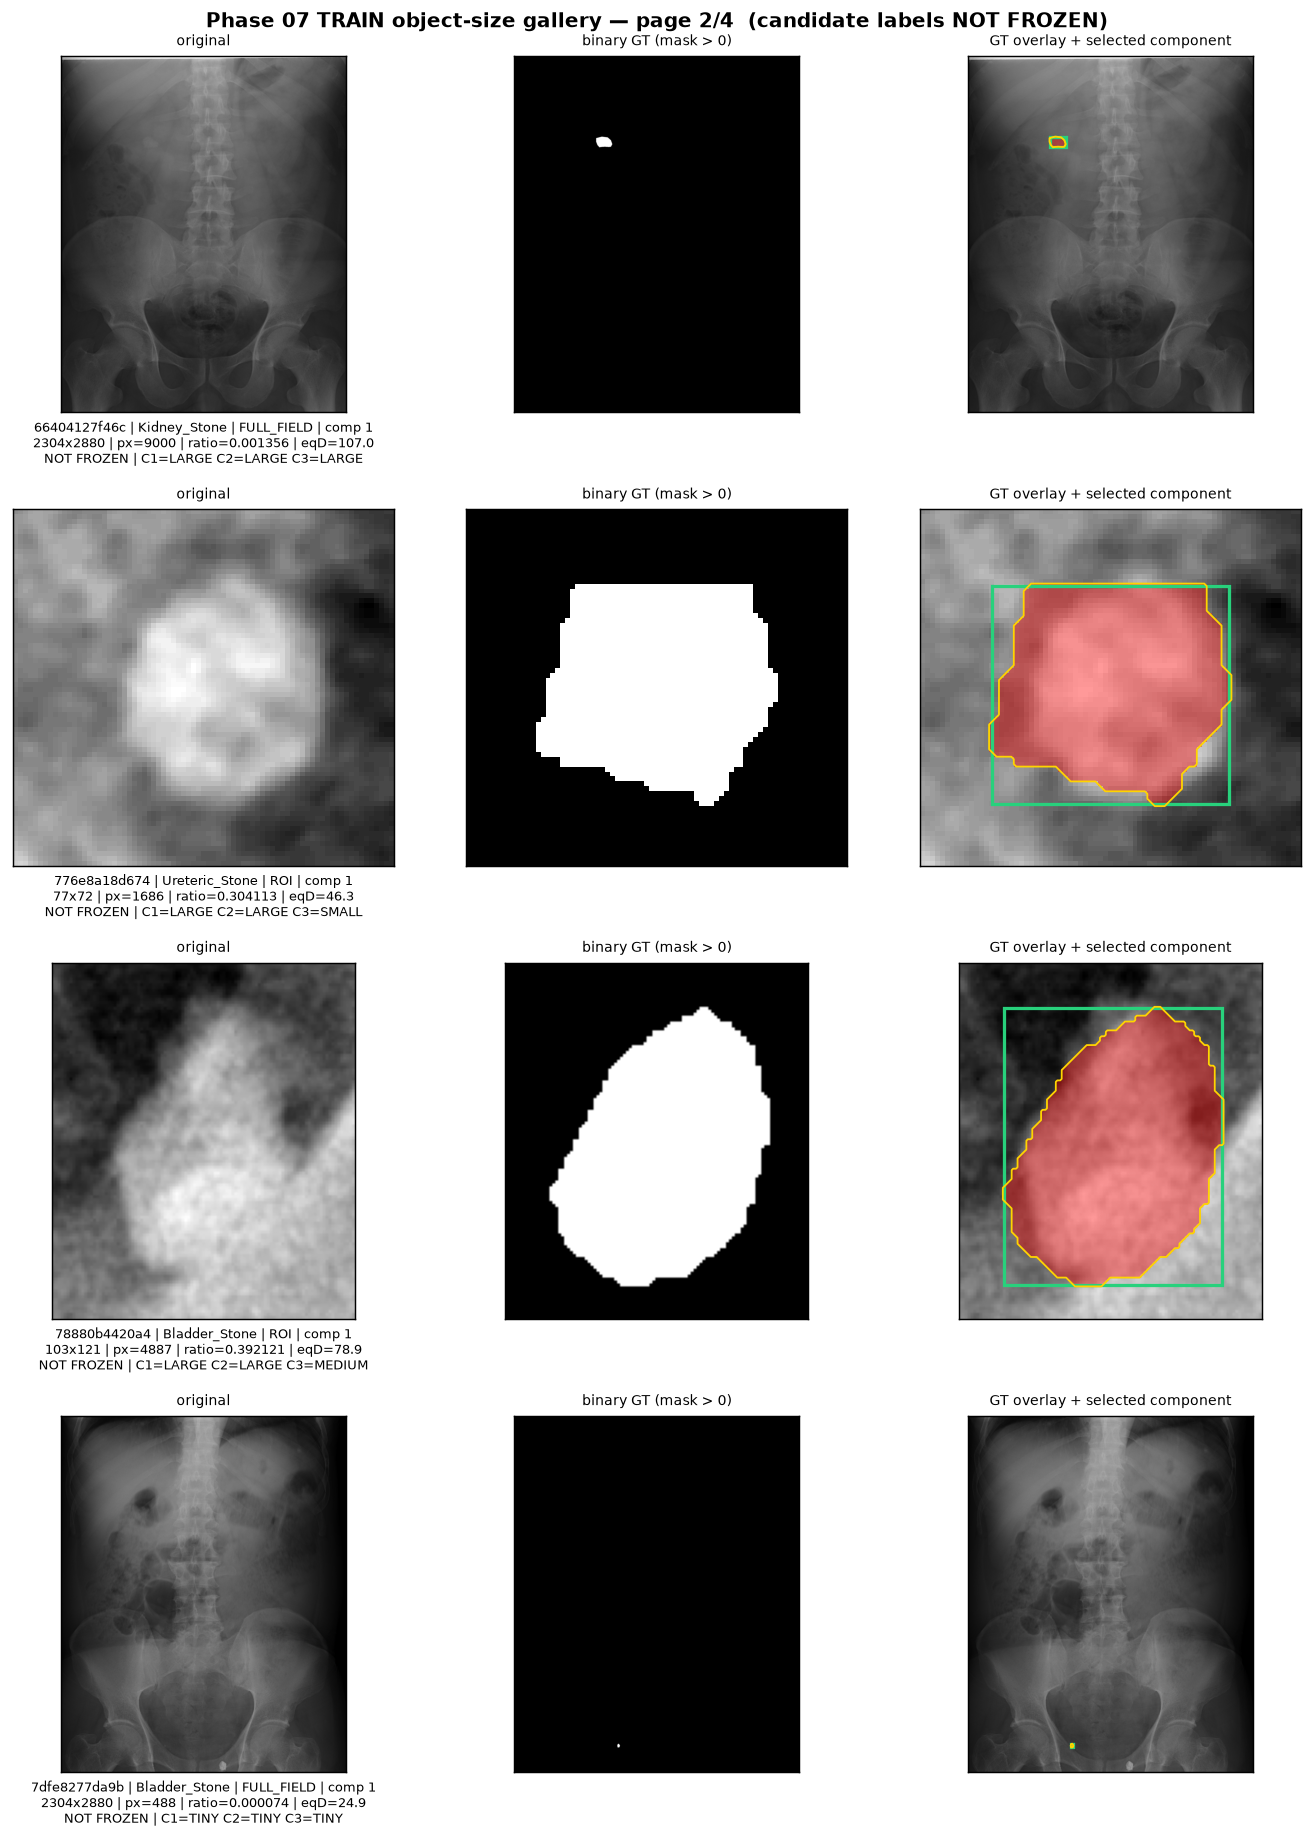

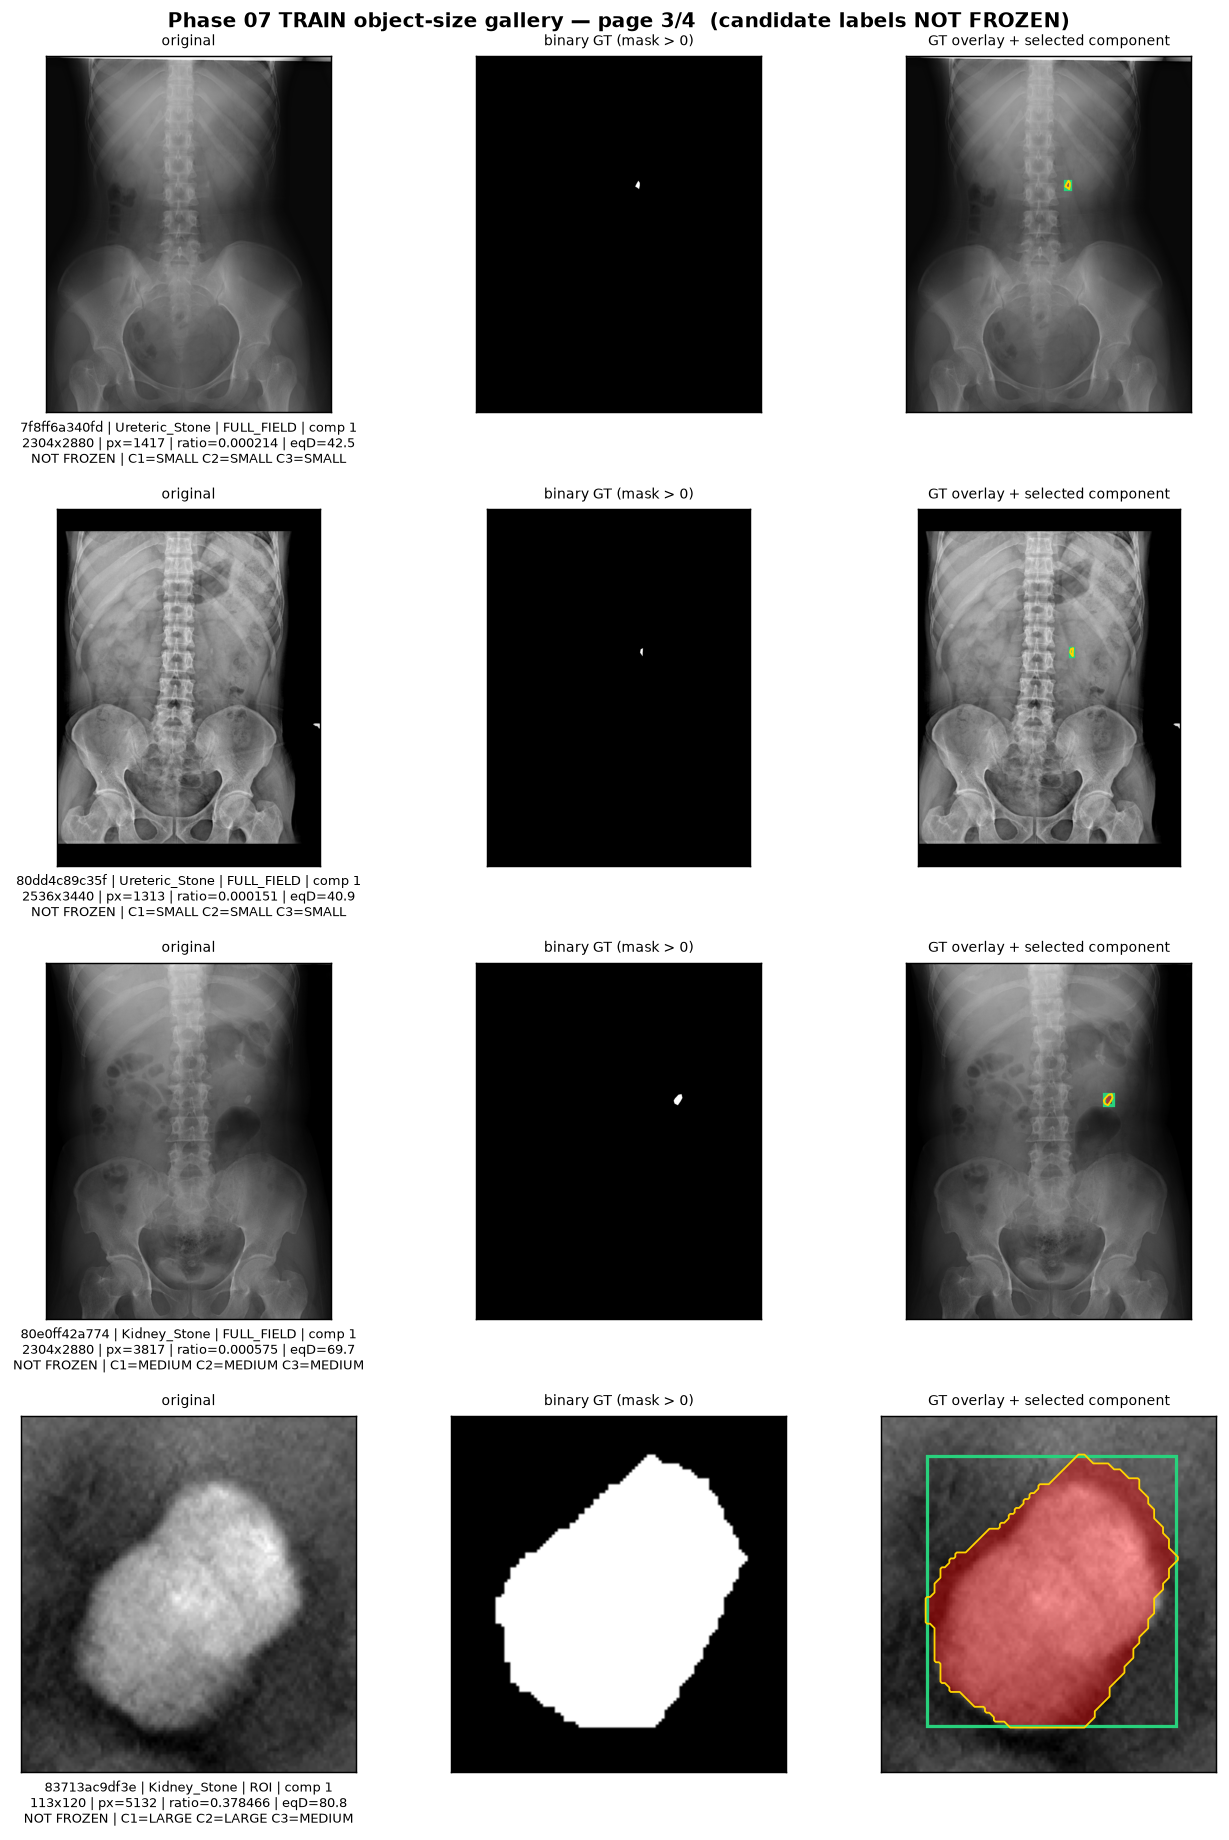

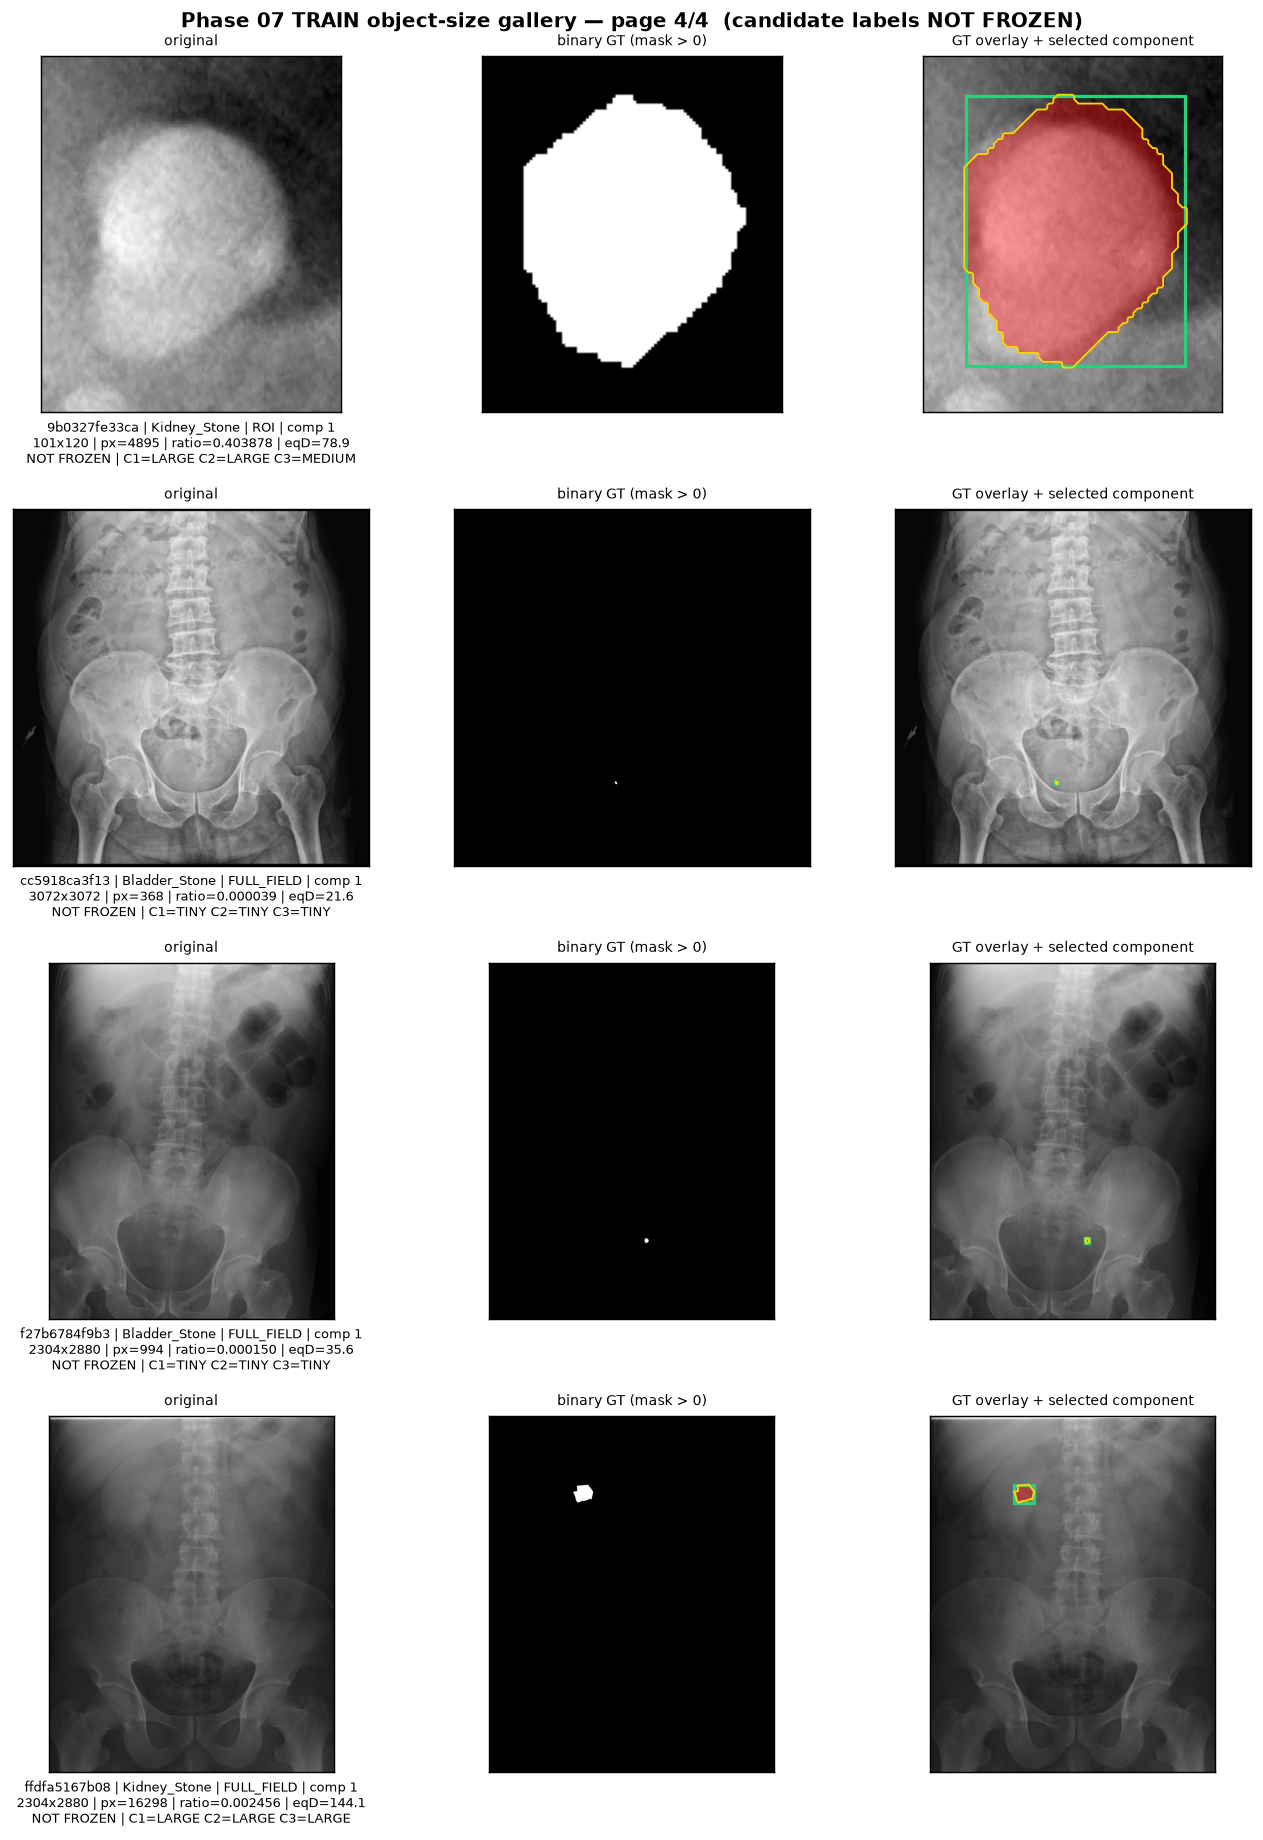

pages: 4 | each case shows original + binary GT + selected component


In [18]:
gal = p7.gallery_pages(sel, obj_df, cases_per_page=4,
                       title='Phase 07 TRAIN object-size gallery')
for i, f in enumerate(gal, 1):
    gp = p7.save_fig(f, FIGDIR / f'phase07_train_gallery_page{i:02d}.png')
    display(IPImage(filename=str(gp)))
print('pages:', len(gal), '| each case shows original + binary GT + selected component')

## 17. Candidate Comparison Matrix

In [19]:
rows = []
for c in candidates:
    for scope in ('ALL_TRAIN', 'FULL_FIELD', 'ROI'):
        sub = cand_sum[(cand_sum['candidate_id'] == c['candidate_id']) &
                       (cand_sum['scope'] == scope)]
        if sub.empty:
            continue
        rec = {'candidate': c['candidate_id'], 'metric': c['metric'], 'scope': scope,
               'applicable_objects': int(sub['applicable_objects'].iloc[0])}
        for s in p7.STRATA:
            r = sub[sub['stratum'] == s]
            rec[f'{s.lower()}_objects'] = int(r['objects'].iloc[0]) if len(r) else 0
            rec[f'{s.lower()}_pct'] = float(r['prevalence_pct'].iloc[0]) if len(r) else 0.0
        rows.append(rec)
cmp_df = pd.DataFrame(rows)
display(cmp_df[cmp_df['scope'] == 'FULL_FIELD'])

,candidate,metric,scope,applicable_objects,tiny_objects,tiny_pct,small_objects,small_pct,medium_objects,medium_pct,large_objects,large_pct
1,C1_HISTORICAL_kub_size_v1,component_ratio,FULL_FIELD,1161,291,25.064599,289,24.892334,290,24.978467,291,25.064599
4,C2_NORMALIZED_EQ_DIAMETER,normalized_equivalent_diameter,FULL_FIELD,1161,291,25.064599,290,24.978467,290,24.978467,290,24.978467
7,C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX,equivalent_diameter,FULL_FIELD,1161,291,25.064599,290,24.978467,290,24.978467,290,24.978467


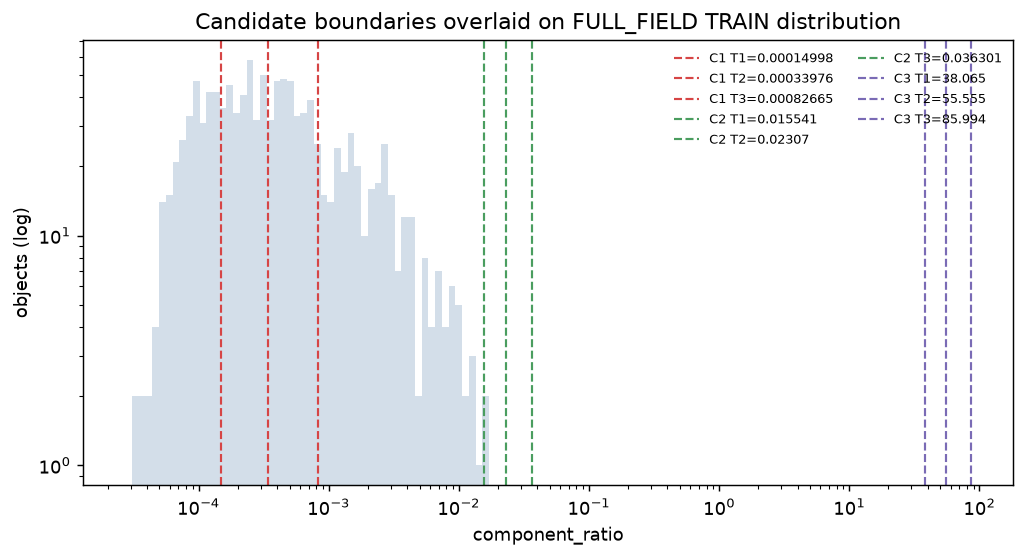

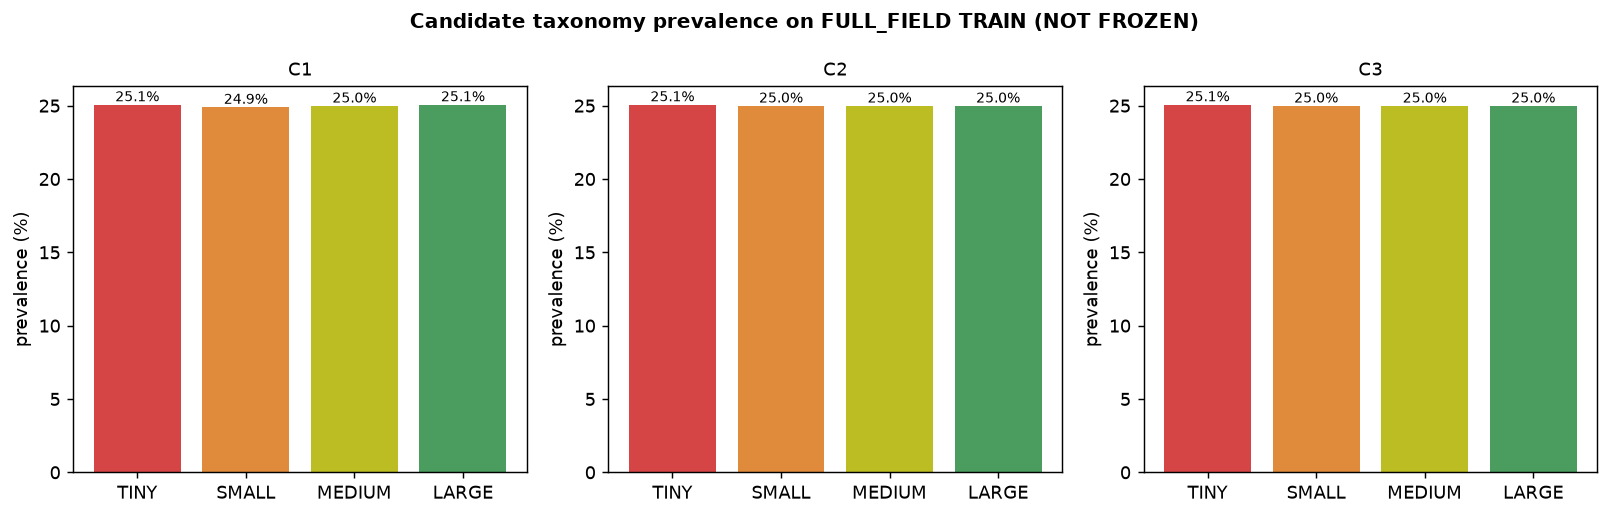

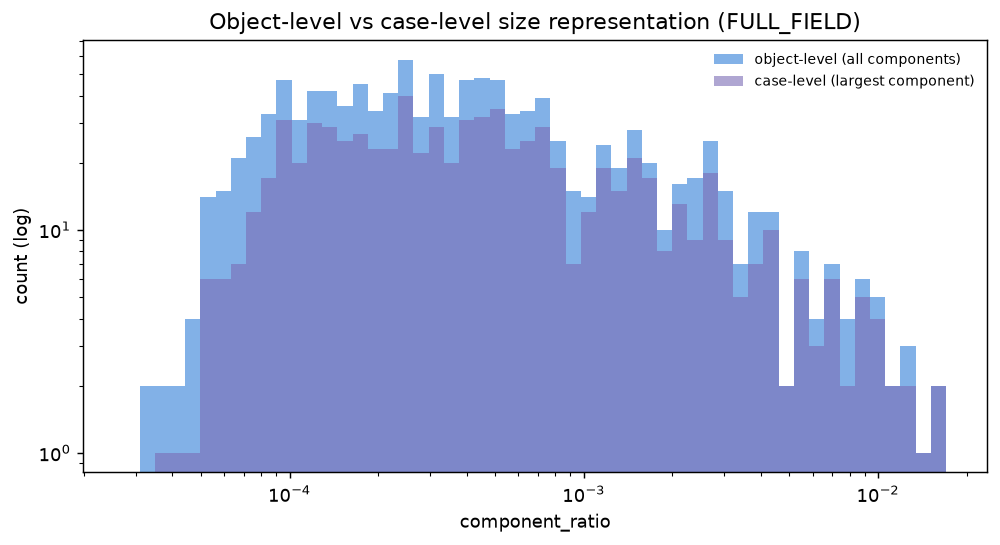

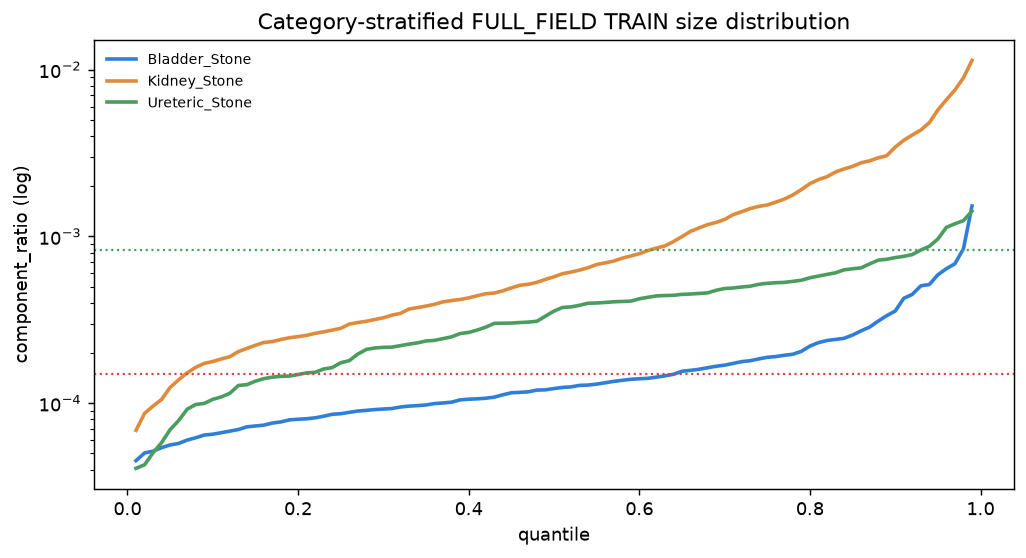

In [20]:
display(IPImage(filename=str(FIGDIR / 'phase07_candidate_threshold_overlays.png')))
display(IPImage(filename=str(FIGDIR / 'phase07_candidate_taxonomy_prevalence.png')))
display(IPImage(filename=str(FIGDIR / 'phase07_object_vs_case_comparison.png')))
display(IPImage(filename=str(FIGDIR / 'phase07_category_stratified_ff_size.png')))

## 18. Scientific Recommendation to Supervisor

**Status: `RECOMMENDED_FOR_SUPERVISOR_REVIEW`** — not final, not frozen, not canonical.

In [21]:
rec = {
    'status': 'RECOMMENDED_FOR_SUPERVISOR_REVIEW',
    'candidate_id': 'C1_HISTORICAL_kub_size_v1',
    'rationale': [
        'Exact historical continuity: identical metric, unit, connectivity, coordinate system and boundaries',
        'Already native-scale-normalized (component area / native image area)',
        'Downstream object-recall work in Phases 10-14 was built on these labels',
        'Boundaries are transparent TRAIN-only quartiles',
    ],
    'alternatives': {
        'C2_NORMALIZED_EQ_DIAMETER': 'Prefer if ROI coverage is required; the only candidate '
                                     'that is meaningfully comparable across both regimes.',
        'C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX': 'Prefer if reviewers need the most human-readable '
                                              'unit (pixels); FULL_FIELD-only by construction.',
    },
    'explicitly_not_used': [
        'VAL prevalence', 'VAL sample counts', 'model performance on VAL',
        'recall/Dice on VAL', 'statistical power on VAL',
    ],
}
print(json.dumps(rec, indent=2))

{
  "status": "RECOMMENDED_FOR_SUPERVISOR_REVIEW",
  "candidate_id": "C1_HISTORICAL_kub_size_v1",
  "rationale": [
    "Exact historical continuity: identical metric, unit, connectivity, coordinate system and boundaries",
    "Already native-scale-normalized (component area / native image area)",
    "Downstream object-recall work in Phases 10-14 was built on these labels",
    "Boundaries are transparent TRAIN-only quartiles"
  ],
  "alternatives": {
    "C2_NORMALIZED_EQ_DIAMETER": "Prefer if ROI coverage is required; the only candidate that is meaningfully comparable across both regimes.",
    "C3_FULLFIELD_NATIVE_EQ_DIAMETER_PX": "Prefer if reviewers need the most human-readable unit (pixels); FULL_FIELD-only by construction."
  },
  "explicitly_not_used": [
    "VAL prevalence",
    "VAL sample counts",
    "model performance on VAL",
    "recall/Dice on VAL",
    "statistical power on VAL"
  ]
}


## 19. Limitations

- Threshold design uses **KUB TRAIN only**; VAL is deliberately unused here.
- **TEST medical content remains locked** (0 reads, 0 visualisations, 0 metrics).
- The historical cut values were derived on **phase4_v2** FULL_FIELD TRAIN components
  (contaminated-era membership); re-deriving them on clean-v3 would change the numbers.
- Aggregate geometry mixes two acquisition regimes and is a **mixture statistic**.
- Candidate labels are **exploratory** and must not be treated as canonical.
- Quartile-based binning guarantees ~25% per bin **on the derivation population**; it is
  not an absolute geometric criterion.
- No literature claim is made: no external sources were consulted.

## 20. Decision Required Before Freeze

The supervisor must decide:

1. **Unit**: confirm object-level (recommended) and whether a case-level rule is needed.
2. **Candidate**: C1 (historical continuity), C2 (cross-regime), or C3 (interpretable pixels).
3. **Acquisition scope**: Option A (FULL_FIELD only), B (normalized, both), or C (separate).
4. **Boundary freeze**: authorise Part 1B to freeze the chosen cut values.
5. **VAL role**: confirm VAL stays evaluation-only after the freeze.

**Nothing is frozen by this notebook.**

## 21. Artifact Hashes

In [22]:
ledger = {
    'manifest_version': p7.ACTIVE_MANIFEST_VERSION,
    'manifest_hashes': {k: p7.sha256_file(p7.MANIFEST_DIR / f'{k}.csv')
                        for k in ('train', 'val', 'test', 'quarantined')},
    'historical_definition_sources': {
        s['source_file']: s['sha256'] for s in hist_audit['sources']},
    'train_objects': int(len(obj_df)),
    'train_cases': int(len(case_df)),
    'gallery_selection_sha': SELECTION_SHA,
    'candidates': {c['candidate_id']: c['cut_values'] for c in candidates},
    'threshold_frozen': False,
    'val_used_for_threshold_selection': False,
}
print(json.dumps(ledger, indent=2))
print()
reg = p7.final_table_registry(TABLES)
display(reg)
print('FINAL TABLE COUNT:', int(reg['exists'].sum()))

{
  "manifest_version": "phase4_v3",
  "manifest_hashes": {
    "train": "28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6",
    "val": "082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315",
    "test": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727",
    "quarantined": "a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c"
  },
  "historical_definition_sources": {
    "src/analysis/kub_object_size.py": "4dbf35d074cfe505f43ed3fe6325557b9cb0da900cdb8402584345ef3e55c58e",
    "src/analysis/kub_characterization.py": "7726f70dfe2470d23a9e1df7eca5c8fc7a3f884d1a02fb5db9c564474e74f34b",
    "src/data/transforms.py": "8a8b636b58843d36810ebf5f3527a8ca1287b93483b962d5cf8e323a92566223",
    "reports/audits/kub_object_size_thresholds.json": "20d3ba58fd5d1272aa52c7c6f82a074b1c903d38de8896ad3a78c3af95eb5043",
    "reports/audits/kub_object_size_provenance.json": "024d36495a1062cbc9fd2beb5500a910411997cbe3b47307b90aaac53d34a8b2",
    "report

,table,exists,bytes,sha256
0,phase07_kub_v3_train_object_geometry.csv,True,1017395,2094d2ed4fae02f05ad9b24e938a5707c73e3da794dcd5...
1,phase07_kub_v3_train_case_size_summary.csv,True,391526,d1b0c42f04ff4ac7ea26b7be919b04b44c20006f35cea7...
2,phase07_kub_v3_train_size_quantiles.csv,True,9572,8c3b47a008cd530647f62a98c45986590b16aabd885302...
3,phase07_candidate_taxonomy_comparison.csv,True,9776,7d42cf263ad865aabe8b15f34609943028c51dead14bfe...
4,phase07_candidate_boundary_sensitivity.csv,True,1599,3f80a4f3246a1b8ed5a17b5a6b36d1da37df9f17c7ab87...
5,phase07_historical_definition_clean_v3_train.csv,True,1643,77bf51beed28b55c5d68bf0671f4366172bad5993d7357...
6,phase07_train_gallery_selection.csv,True,11987,79b45076aaa736c73a81c4c055906bf2c241e5a6f42ef6...


FINAL TABLE COUNT: 7


In [23]:
assertion = p7.test_lock_assertion(ktr, ktest, obj_df)
print('=' * 62)
print('PHASE 07 PART 1A — GOVERNANCE ASSERTION')
print('=' * 62)
for k, v in assertion.items():
    print(f'{k:38s}: {v}')
print('=' * 62)

PHASE 07 PART 1A — GOVERNANCE ASSERTION
ACTIVE MANIFEST                       : phase4_v3
KUB TRAIN CASES                       : 1978
KUB TEST (metadata only)              : 558
TRAIN OBJECTS                         : 2375
VAL USED FOR THRESHOLD SELECTION      : NO
VAL CONTENT READS FOR PART1A          : 0
TEST CONTENT READS                    : 0
TEST VISUALIZATIONS                   : 0
TEST METRICS                          : 0
THRESHOLD FROZEN                      : NO
PHASE 08 STARTED                      : NO
